# COMP-2331 Data Analysis with Libraries (283810) - 2331 Assignment 2

- Student: Amanda Dadalt Makino - 0434820

- Submission: October 11, 2026


## Importing data
- Import both datasets using Pandas.
- Use functions like head(), info(), and describe() to explore the data.


In [1338]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#Display options
pd.set_option('display.max_rows', None) #Show all rows
pd.set_option('display.max_columns', None) #Show all columns
pd.set_option('display.width', None) #Prevent wrapping
pd.set_option('display.max_colwidth', None) #Prevent truncating content

In [1339]:
sales_data = 'sample_data/sales_data.csv'

df_sales_data = pd.read_csv(sales_data)

print("Sales Data Info:")
df_sales_data.head(11)


Sales Data Info:


,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario
4,2023-11-03,Tents,Tent XL,14.0,1308.21,Manitoba
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitobia
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba


In [1340]:
# promotions_data_txt = 'sample_data/promotions_data.txt'

df_promotions_data = pd.read_csv('sample_data/promotions_data.txt', sep="\t")

print("Promotions Data Info:")
df_promotions_data.head(11)

Promotions Data Info:


,Product_Name,Promotion_Type,Discount_Percentage,Start_Date,End_Date
0,Winter Coat XL,Discount,20,2022-12-02,2023-03-02
1,Tent X-Large,Clearance,30,2023-05-02,2023-07-30
2,Fishing Rod,Bundle,15,2023-06-01,2023-08-30
3,Snow Pants,Discount,25,2023-02-01,2023-03-31
4,Fishing Reel,Bundle,10,2023-09-01,2023-09-30


## Clean the Data

- Standardize date formats (e.g., MM/DD/YYYY → YYYY-MM-DD).
- Fix region names (e.g., “Manitobia” → “Manitoba”, “MB” → “Manitoba”).
- Standardize product names (e.g., “Tent XL” vs. “Tent X-Large”).
- Handle missing values:
    - Decide whether to fill or drop (explain your choices).
- Clean sales amounts (remove currency symbols, ensure numeric).


### Standarize date formats

In [1341]:
# Standardize date formats
df_sales_data['Date'] = pd.to_datetime(df_sales_data['Date'])

print("Sales Data with Date formatted:")
df_sales_data.head(11)

Sales Data with Date formatted:


,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario
4,2023-11-03,Tents,Tent XL,14.0,1308.21,Manitoba
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitobia
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba


In [1342]:
# Standardize date formats
df_promotions_data["Start_Date"] = pd.to_datetime(df_promotions_data["Start_Date"])
df_promotions_data["End_Date"] = pd.to_datetime(df_promotions_data["End_Date"])

print("Promotions Data Info with the dates formatted:")
df_promotions_data.head(11)

Promotions Data Info with the dates formatted:


,Product_Name,Promotion_Type,Discount_Percentage,Start_Date,End_Date
0,Winter Coat XL,Discount,20,2022-12-02,2023-03-02
1,Tent X-Large,Clearance,30,2023-05-02,2023-07-30
2,Fishing Rod,Bundle,15,2023-06-01,2023-08-30
3,Snow Pants,Discount,25,2023-02-01,2023-03-31
4,Fishing Reel,Bundle,10,2023-09-01,2023-09-30


### Fixing Region names

In [1343]:
# Fix region names
df_sales_data['Region'] = df_sales_data['Region'].str.strip().str.title()

# Replace different spellings of the same category with a standard value
df_sales_data['Region'] = df_sales_data['Region'].replace({
    "Manitobia": "Manitoba",
    "MB": "Manitoba",
    "Mb": "Manitoba",
    "SK": "Saskatchewan",
    "Sask": "Saskatchewan",
    "Northwestern Ont.": "Northwestern Ontario"
})

print("Sales Data with Regions formatted:")
df_sales_data.head(11)

Sales Data with Regions formatted:


,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario
4,2023-11-03,Tents,Tent XL,14.0,1308.21,Manitoba
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitoba
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba


### Standarize product names

In [1344]:
# Standarize products names
df_sales_data["Product_Name"] = df_sales_data["Product_Name"].str.strip().str.title()

df_sales_data['Product_Name'] = df_sales_data['Product_Name'].replace({
    "Tent XL": "Tent X-Large",
    "Tent X-Large": "Tent X-Large"
})

print("Sales Data Info with standarized product names:")
df_sales_data.head(11)


Sales Data Info with standarized product names:


,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario
4,2023-11-03,Tents,Tent Xl,14.0,1308.21,Manitoba
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitoba
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba


### Remove Currency Symbols / Ensure Numeric

In [1345]:
df_sales_data["Sales_Amount"] = (df_sales_data["Sales_Amount"].astype(str).str.replace(r"[^0-9\.-]", "", regex=True).astype(float))

print("Sales Data with cleaned Sales Amount:")
df_sales_data.head(11)

Sales Data with cleaned Sales Amount:


,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario
4,2023-11-03,Tents,Tent Xl,14.0,1308.21,Manitoba
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitoba
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba


### Handle Missing Values

In [1346]:
# Count the number of missing values in each column
missing_counts = df_sales_data.isna().sum()

print("Missing values per column:\n", missing_counts)

Missing values per column:
 Date                0
Product_Category    0
Product_Name        0
Units_Sold          7
Sales_Amount        7
Region              0
dtype: int64


In [1347]:
df_sales_data = df_sales_data.dropna(subset=["Units_Sold", "Sales_Amount"])

print(f"Dropped rows with missing Units_Sold or Sales_Amount "
      f"because these are essential for sales.")


Dropped rows with missing Units_Sold or Sales_Amount because these are essential for sales.


In [1348]:
# Checking if the values were correctly dropped
missing_counts = df_sales_data.isna().sum()

print("Missing values per column:\n", missing_counts)

Missing values per column:
 Date                0
Product_Category    0
Product_Name        0
Units_Sold          0
Sales_Amount        0
Region              0
dtype: int64


In [1349]:
# Capture the Month and Year into new columns
df_sales_data["Year"] = df_sales_data["Date"].dt.year
df_sales_data["Month"] = df_sales_data["Date"].dt.month

df_sales_data.head(11)

,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region,Year,Month
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba,2023,4
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba,2023,6
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan,2023,8
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario,2023,4
4,2023-11-03,Tents,Tent Xl,14.0,1308.21,Manitoba,2023,11
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario,2022,4
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan,2023,9
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario,2022,2
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitoba,2023,2
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba,2023,12


In [1350]:
# Define a function to assign seasons
def get_season(dt):
    m = dt.month
    if m in [12, 1, 2]:
        return "Winter"
    elif m in [3, 4, 5]:
        return "Spring"
    elif m in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"

# Apply the function to create a Season column
df_sales_data["Season"] = df_sales_data["Date"].apply(get_season)

print("Sales Data with Year, Month, Season:")
print(df_sales_data.head(11))

Sales Data with Year, Month, Season:
         Date Product_Category       Product_Name  Units_Sold  Sales_Amount  \
0  2023-04-22     Hiking Boots      Boot Pro 3000        11.0       1320.32   
1  2023-06-24     Hiking Boots  Trail Runner 2000         7.0       1183.11   
2  2023-08-19     Fishing Gear        Fishing Rod         5.0       1553.63   
3  2023-04-22     Hiking Boots  Trail Runner 2000        14.0       1316.47   
4  2023-11-03            Tents            Tent Xl        14.0       1308.21   
5  2022-04-16     Hiking Boots  Trail Runner 2000         8.0       1113.18   
6  2023-09-15     Fishing Gear       Fishing Reel        16.0       1597.73   
7  2022-02-05     Hiking Boots  Trail Runner 2000        18.0       1748.87   
8  2023-02-18            Tents       Tent X-Large        17.0       1860.06   
9  2023-12-16            Tents       Tent X-Large        15.0        916.38   
10 2022-02-05     Hiking Boots  Trail Runner 2000        16.0       1747.45   

              

## Merge Promotions Data
- Join on Product_Name and flag sales that occurred during a promotion period (create a new column: Promoted).
- Assume a sale is promoted if the sale Date falls within the Start_Date and End_Date of any promotion for that product.


In [1351]:
# Merge dataframes joined on "Product Name"
df_merged = pd.merge(df_sales_data, df_promotions_data, on="Product_Name", how="left")

print(f"This is both datas merged together:")
df_merged.head(11)

This is both datas merged together:


,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region,Year,Month,Season,Promotion_Type,Discount_Percentage,Start_Date,End_Date
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba,2023,4,Spring,NaN,NaN,NaT,NaT
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba,2023,6,Summer,NaN,NaN,NaT,NaT
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan,2023,8,Summer,Bundle,15.0,2023-06-01,2023-08-30
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario,2023,4,Spring,NaN,NaN,NaT,NaT
4,2023-11-03,Tents,Tent Xl,14.0,1308.21,Manitoba,2023,11,Fall,NaN,NaN,NaT,NaT
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario,2022,4,Spring,NaN,NaN,NaT,NaT
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan,2023,9,Fall,Bundle,10.0,2023-09-01,2023-09-30
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario,2022,2,Winter,NaN,NaN,NaT,NaT
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitoba,2023,2,Winter,Clearance,30.0,2023-05-02,2023-07-30
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba,2023,12,Winter,Clearance,30.0,2023-05-02,2023-07-30


In [1352]:
# Flag Sales that occurred during a promotion period

# Create new column with a default value of false
df_merged['Promoted'] = False

# Create a mask to filter between start and end dates
mask = (
    df_merged["Start_Date"].notna() &
    (df_merged['Date'] >= df_merged['Start_Date']) &
    (df_merged['Date'] <= df_merged['End_Date'])
)

# Use label based indexing to apply the mask to the data
# If any of the conditions above evaluate to true, Promoted will be updated to true
df_merged.loc[mask, 'Promoted'] = True

# Verify
print(f"Here is the data with the sales that were promoted:")
df_merged.head(11)

Here is the data with the sales that were promoted:


,Date,Product_Category,Product_Name,Units_Sold,Sales_Amount,Region,Year,Month,Season,Promotion_Type,Discount_Percentage,Start_Date,End_Date,Promoted
0,2023-04-22,Hiking Boots,Boot Pro 3000,11.0,1320.32,Manitoba,2023,4,Spring,NaN,NaN,NaT,NaT,False
1,2023-06-24,Hiking Boots,Trail Runner 2000,7.0,1183.11,Manitoba,2023,6,Summer,NaN,NaN,NaT,NaT,False
2,2023-08-19,Fishing Gear,Fishing Rod,5.0,1553.63,Saskatchewan,2023,8,Summer,Bundle,15.0,2023-06-01,2023-08-30,True
3,2023-04-22,Hiking Boots,Trail Runner 2000,14.0,1316.47,Northwestern Ontario,2023,4,Spring,NaN,NaN,NaT,NaT,False
4,2023-11-03,Tents,Tent Xl,14.0,1308.21,Manitoba,2023,11,Fall,NaN,NaN,NaT,NaT,False
5,2022-04-16,Hiking Boots,Trail Runner 2000,8.0,1113.18,Northwestern Ontario,2022,4,Spring,NaN,NaN,NaT,NaT,False
6,2023-09-15,Fishing Gear,Fishing Reel,16.0,1597.73,Saskatchewan,2023,9,Fall,Bundle,10.0,2023-09-01,2023-09-30,True
7,2022-02-05,Hiking Boots,Trail Runner 2000,18.0,1748.87,Northwestern Ontario,2022,2,Winter,NaN,NaN,NaT,NaT,False
8,2023-02-18,Tents,Tent X-Large,17.0,1860.06,Manitoba,2023,2,Winter,Clearance,30.0,2023-05-02,2023-07-30,False
9,2023-12-16,Tents,Tent X-Large,15.0,916.38,Manitoba,2023,12,Winter,Clearance,30.0,2023-05-02,2023-07-30,False


## Visualize the Data
- When are sales strongest? Are there clear seasonal trends?
- Which product categories generate the most revenue?
- Are there regional differences in sales performance?
- Do promotions increase sales?


In [1353]:
sns.set_theme(style="whitegrid")

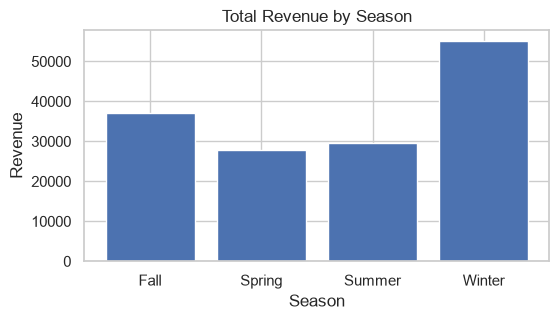

In [1354]:
# When are sales strongest? Are there clear seasonal trends?

season_summary = df_merged.groupby("Season", as_index=False)["Sales_Amount"].sum()

# Make it into a list
seasons = season_summary["Season"].tolist()
revenue = season_summary["Sales_Amount"].tolist()

plt.figure(figsize=(6, 3))
plt.bar(seasons, revenue)
plt.title("Total Revenue by Season")
plt.xlabel("Season")
plt.ylabel("Revenue")
plt.show()

- Answer: Sales are strongest during winter time

- Why this chart: I chose a Bar chart of total revenue by season because the x‑axis is a small set of categories (Winter, Spring, Summer, Fall), and I want to compare their total revenue side by side.

- What it shows: The height of each bar shows how much revenue Prairie Outfitters earns in each season. Taller bars indicate stronger sales; this makes it easy to see which seasons are the strongest and whether there is a clear seasonal pattern in sales.

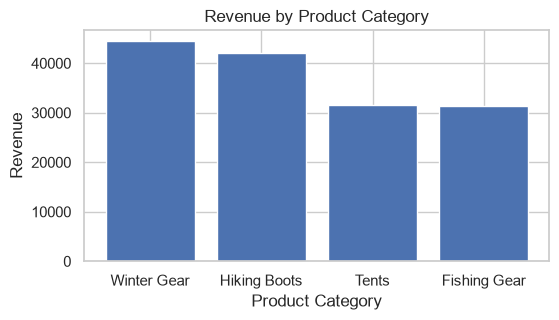

In [1355]:
# Which product categories generate the most revenue?

category_summary = (
    df_merged.groupby("Product_Category", as_index=False)["Sales_Amount"].sum()
    .sort_values("Sales_Amount", ascending=False)
)

# Make it into a list
categories = category_summary["Product_Category"].tolist()
category_revenue = category_summary["Sales_Amount"].tolist()

plt.figure(figsize=(6, 3))
plt.bar(categories, category_revenue)
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.show()

- Answer: Winter Gear generates the most revenue

- Why this chart: I chose a Bar chart because I am comparing total revenue across a few product categories. A bar chart clearly shows which categories generate the most money

- What it shows: Each bar represents the total sales amount for one category. The chart highlights the top earning categories and shows which products contribute most to overall revenue

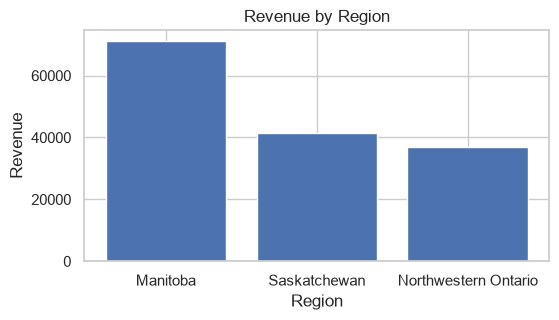

In [1356]:
# Are there regional differences in sales performance?

region_summary = (
    df_merged.groupby("Region", as_index=False)["Sales_Amount"].sum()
    .sort_values("Sales_Amount", ascending=False)
)

# Make it into a list
regions = region_summary["Region"].tolist()
region_revenue = region_summary["Sales_Amount"].tolist()

plt.figure(figsize=(6, 3))
plt.bar(regions, region_revenue)
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

- Answer: Manitoba seem to produce the most revenue out of the different regions.

- Why this chart: Regions are another set of small categories. A bar chart makes it easy to compare how well the store is performing in each region

- What it shows: Each bar shows the total revenue from that region. You can easily see which region has the highest sales and whether there are noticeable differences between Manitoba, Saskatchewan, and Northwestern Ontario

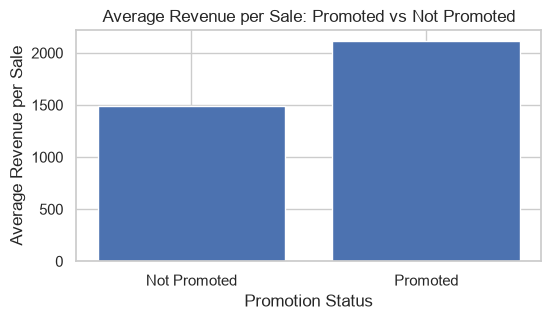

In [ ]:
# Do promotions increase sales?

promo_summary = df_merged.groupby("Promoted", as_index=False)["Sales_Amount"].mean()

# Transform True/False into Promoted/Not Promoted
promo_summary["Promoted_Label"] = promo_summary["Promoted"].map(
    {False: "Not Promoted", True: "Promoted"}
)

# Make it into a list
promo_labels = promo_summary["Promoted_Label"].tolist()
promo_avg_revenue = promo_summary["Sales_Amount"].tolist()

plt.figure(figsize=(6, 3))
plt.bar(promo_labels, promo_avg_revenue)
plt.title("Average Revenue per Sale: Promoted vs Not Promoted")
plt.xlabel("Promotion Status")
plt.ylabel("Average Revenue per Sale")
plt.show()

- Answer: Yes, promotions increases sales

- Why this chart: I am comparing two groups, a simple bar chart shows the difference in average sale amount between these two groups

- What it shows: One bar shows the average revenue for promoted sales, and the other shows the average for non‑promoted sales